# Empathic vs Non-Empathic Agent Comparison

This notebook compares two conditions:
1. **Non-Empathic Agents** (`empathy_alpha = 0`): Agents only care about their own satisfaction
2. **Empathic Agents** (`empathy_alpha = 0.5`): Agents consider others' emotional state when consuming resources

## Environment Setup
- **Grid**: 5×5 (25 cells)
- **Agents**: 5
- **Initial Resources**: 10
- **Regeneration**: Dynamic (fewer resources = lower respawn probability)

## Metrics Tracked
1. **Resource Depletion Step**: Step at which resources reach 0 (or episode end if never depleted)
2. **Resources Remaining**: Number of resources left at episode end
3. **Gini Coefficient**: Inequality measure of resource consumption across agents
4. **Average Inter-Agent Distance**: Mean Manhattan distance between all agent pairs
5. **Total Consumption per Agent**: How many resources each agent consumed
6. **Satisfaction Distribution**: Final satisfaction levels across agents

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import torch
import warnings
warnings.filterwarnings('ignore')

from env_2d import EmpathicGridEnv
from agent_2d import DQNAgent

# Set random seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# ============================================================
# GPU CONFIGURATION - Maximize Performance
# ============================================================
print("="*60)
print("HARDWARE CONFIGURATION")
print("="*60)

if torch.cuda.is_available():
    # Use GPU
    DEVICE = torch.device("cuda")
    print(f"✓ CUDA Available: Using GPU")
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  CUDA Version: {torch.version.cuda}")
    print(f"  Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    
    # Performance optimizations
    torch.backends.cudnn.benchmark = True  # Auto-tune for best performance
    torch.backends.cudnn.enabled = True
    print(f"  cuDNN Enabled: {torch.backends.cudnn.enabled}")
    print(f"  cuDNN Benchmark: {torch.backends.cudnn.benchmark}")
else:
    DEVICE = torch.device("cpu")
    print(f"✗ CUDA Not Available: Using CPU")
    # CPU optimizations
    torch.set_num_threads(torch.get_num_threads())
    print(f"  CPU Threads: {torch.get_num_threads()}")

print("="*60)
print("Imports completed successfully!")

HARDWARE CONFIGURATION
✓ CUDA Available: Using GPU
  GPU: NVIDIA GeForce RTX 4050 Laptop GPU
  CUDA Version: 12.1
  Memory: 6.4 GB
  cuDNN Enabled: True
  cuDNN Benchmark: True
Imports completed successfully!


In [2]:
# Quick GPU verification - Create a test agent and verify it's on GPU
print("="*60)
print("GPU VERIFICATION TEST")
print("="*60)

test_env = EmpathicGridEnv(
    grid_size=5, num_agents=1, num_resources=5, vision_radius=2,
    exploit_reward=1.0, empathic_penalty=-1.0, step_cost=-0.01, max_steps=50
)

test_agent = DQNAgent(
    agent_id=0,
    state_size=test_env.observation_space.shape,
    action_size=test_env.action_space.n,
    learning_rate=0.001, gamma=0.99, epsilon=1.0,
    epsilon_decay=0.995, epsilon_min=0.1,
    batch_size=16, hidden_size=64, update_target_every=20
)

# Check device
policy_device = next(test_agent.policy_network.parameters()).device
print(f"Test agent device: {policy_device}")

if policy_device.type == 'cuda':
    print("✓ GPU acceleration CONFIRMED!")
    
    # IMPORTANT: Link agent to env BEFORE calling reset()
    test_env.agents = [test_agent.agent]
    test_obs, _ = test_env.reset()
    
    import time
    start = time.time()
    for _ in range(100):
        _ = test_agent.select_action(test_obs[0], training=False)
    elapsed = (time.time() - start) * 1000
    print(f"  100 forward passes: {elapsed:.1f}ms ({elapsed/100:.2f}ms/pass)")
else:
    print("ℹ Running on CPU (GPU not available)")

# Cleanup
del test_env, test_agent
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("="*60)

GPU VERIFICATION TEST
Agent 0 using device: cuda
  GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Test agent device: cuda:0
✓ GPU acceleration CONFIRMED!
  100 forward passes: 275.6ms (2.76ms/pass)


In [3]:
def compute_gini_coefficient(values):
    """
    Compute the Gini coefficient for a list of values.
    Gini = 0 means perfect equality (everyone has the same)
    Gini = 1 means perfect inequality (one person has everything)
    """
    values = np.array(values, dtype=float)
    if len(values) == 0 or np.sum(values) == 0:
        return 0.0
    
    # Sort values
    sorted_values = np.sort(values)
    n = len(sorted_values)
    
    # Compute Gini using the formula: G = (2 * sum(i * x_i) - (n + 1) * sum(x_i)) / (n * sum(x_i))
    index = np.arange(1, n + 1)
    return (2 * np.sum(index * sorted_values) - (n + 1) * np.sum(sorted_values)) / (n * np.sum(sorted_values))


def compute_average_inter_agent_distance(positions):
    """
    Compute the average Manhattan distance between all pairs of agents.
    """
    if len(positions) < 2:
        return 0.0
    
    total_distance = 0
    num_pairs = 0
    
    for i in range(len(positions)):
        for j in range(i + 1, len(positions)):
            x1, y1 = positions[i]
            x2, y2 = positions[j]
            total_distance += abs(x1 - x2) + abs(y1 - y2)
            num_pairs += 1
    
    return total_distance / num_pairs if num_pairs > 0 else 0.0


print("Utility functions defined!")
print(f"Test Gini [1,1,1,1,1] = {compute_gini_coefficient([1,1,1,1,1]):.3f} (should be 0)")
print(f"Test Gini [0,0,0,0,10] = {compute_gini_coefficient([0,0,0,0,10]):.3f} (should be ~0.8)")
print(f"Test Gini [1,2,3,4,5] = {compute_gini_coefficient([1,2,3,4,5]):.3f}")

Utility functions defined!
Test Gini [1,1,1,1,1] = 0.000 (should be 0)
Test Gini [0,0,0,0,10] = 0.800 (should be ~0.8)
Test Gini [1,2,3,4,5] = 0.267


In [ ]:
from tqdm import tqdm
import time

def run_experiment(empathy_alpha, num_episodes=100, max_steps=200, seed=42, show_progress=True):
    """
    Run a full experiment with the given empathy_alpha setting.
    Uses GPU acceleration when available.
    
    Args:
        empathy_alpha: 0.0 for non-empathic, 0.5 for empathic
        num_episodes: Number of training episodes
        max_steps: Maximum steps per episode
        seed: Random seed
        show_progress: Show tqdm progress bar
    
    Returns:
        Dictionary containing all tracked metrics per episode
    """
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
    
    start_time = time.time()
    
    # Create environment
    env = EmpathicGridEnv(
        grid_size=5,
        num_agents=5,
        num_resources=10,
        vision_radius=2,
        exploit_reward=1.0,
        empathic_penalty=-2.0,
        empathy_alpha=empathy_alpha,  # KEY PARAMETER
        step_cost=-0.01,
        loop_penalty=-0.05,
        max_steps=max_steps,
        regeneration_mode='dynamic'  # Resources become scarcer over time
    )
    
    # Create DQN agents (they automatically use GPU if available)
    dqn_agents = []
    for agent_id in range(5):
        agent = DQNAgent(
            agent_id=agent_id,
            state_size=env.observation_space.shape,
            action_size=env.action_space.n,
            learning_rate=0.002,
            gamma=0.99,
            epsilon=1.0,
            epsilon_decay=0.995,       # Faster decay to reach learned behavior sooner
            epsilon_min=0.05,          # Lower minimum for clearer learned behavior
            batch_size=32,
            hidden_size=128,
            update_target_every=20
        )
        dqn_agents.append(agent)
    
    # Verify GPU usage (only for first agent)
    if agent_id == 0:
        device = next(dqn_agents[0].policy_network.parameters()).device
        print(f"  Agents running on: {device}")
    
    # Link agents to environment
    env.agents = [agent.agent for agent in dqn_agents]
    
    # Metrics storage
    metrics = {
        'depletion_step': [],           # Step when resources hit 0 (or max_steps if never)
        'resources_remaining': [],       # Resources left at episode end
        'gini_consumption': [],          # Gini coefficient of consumption
        'gini_satisfaction': [],         # Gini coefficient of final satisfaction
        'avg_inter_agent_distance': [],  # Average distance between agents (episode average)
        'total_consumption': [],         # Total resources consumed per episode
        'consumption_per_agent': [],     # List of consumptions per agent
        'final_satisfactions': [],       # Final satisfaction per agent
        'episode_rewards': [],           # Total reward per agent
        'empathic_penalties_count': [],  # Number of empathic penalty events
    }
    
    # Progress bar
    episode_iter = tqdm(range(num_episodes), desc="Training", disable=not show_progress)
    
    for episode in episode_iter:
        obs, _ = env.reset(seed=seed + episode)
        for agent_idx, dqn_agent in enumerate(dqn_agents):
            dqn_agent.reset(observation=obs[agent_idx])
        
        # Episode tracking
        episode_consumption = [0] * 5
        episode_rewards = [0.0] * 5
        episode_distances = []
        depletion_step = max_steps  # Default: never depleted
        empathic_penalty_count = 0
        
        for step in range(max_steps):
            # Track inter-agent distance
            episode_distances.append(compute_average_inter_agent_distance(env.agent_positions))
            
            # Check for resource depletion
            if len(env.resource_positions) == 0 and depletion_step == max_steps:
                depletion_step = step
            
            # Collect actions (batch processing for efficiency)
            actions = []
            for agent_idx, dqn_agent in enumerate(dqn_agents):
                valid_actions = env.get_valid_actions(agent_idx)
                action = dqn_agent.select_action(obs[agent_idx], training=True, valid_actions=valid_actions)
                actions.append(action)
            
            # Step environment
            next_obs, rewards, done, truncated, info = env.step(actions)
            
            # Track consumption and penalties
            for agent_idx in range(5):
                if info['consumed'][agent_idx]:
                    episode_consumption[agent_idx] += 1
                if info['empathic_penalty_events'][agent_idx]:
                    empathic_penalty_count += 1
                episode_rewards[agent_idx] += rewards[agent_idx]
            
            # Update agents
            for agent_idx, dqn_agent in enumerate(dqn_agents):
                valid_actions_next = env.get_valid_actions(agent_idx)
                dqn_agent.step(next_obs[agent_idx], rewards[agent_idx], done, valid_actions=valid_actions_next)
            
            obs = next_obs
            if done:
                break
        
        # Record episode metrics
        final_satisfactions = [agent.get_satisfaction() for agent in env.agents]
        
        metrics['depletion_step'].append(depletion_step)
        metrics['resources_remaining'].append(len(env.resource_positions))
        metrics['gini_consumption'].append(compute_gini_coefficient(episode_consumption))
        metrics['gini_satisfaction'].append(compute_gini_coefficient(final_satisfactions))
        metrics['avg_inter_agent_distance'].append(np.mean(episode_distances))
        metrics['total_consumption'].append(sum(episode_consumption))
        metrics['consumption_per_agent'].append(episode_consumption.copy())
        metrics['final_satisfactions'].append(final_satisfactions.copy())
        metrics['episode_rewards'].append(episode_rewards.copy())
        metrics['empathic_penalties_count'].append(empathic_penalty_count)
        
        # Update progress bar
        if show_progress:
            episode_iter.set_postfix({
                'Resources': len(env.resource_positions),
                'Gini': f"{metrics['gini_consumption'][-1]:.2f}",
                'ε': f"{dqn_agents[0].epsilon:.2f}"
            })
    
    elapsed = time.time() - start_time
    print(f"  Completed in {elapsed:.1f}s ({elapsed/num_episodes*1000:.1f}ms/episode)")
    
    # Clear GPU cache if using CUDA
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    return metrics


print("Experiment function defined (GPU-accelerated)!")
print("  - epsilon_decay: 0.995 (faster)")
print("  - epsilon_min: 0.05 (lower for clearer learned behavior)")

---

## Run Both Conditions

We now run two experiments:
1. **Non-Empathic** (`empathy_alpha = 0`): Agents are selfish
2. **Empathic** (`empathy_alpha = 0.5`): Agents consider others' emotions

In [ ]:
# INCREASED TRAINING for better learning differentiation
NUM_EPISODES = 300  
MAX_STEPS = 200

# Show GPU memory before training
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()
    print(f"GPU Memory before training: {torch.cuda.memory_allocated() / 1e6:.1f} MB")

print(f"\nTraining for {NUM_EPISODES} episodes (increased for better learning)")
print(f"Epsilon decay: 0.998 → final epsilon ≈ {1.0 * (0.998 ** NUM_EPISODES):.3f}")

print("\n" + "="*60)
print("CONDITION 1: NON-EMPATHIC AGENTS (empathy_alpha = 0)")
print("="*60)
print("Agents only care about their own reward, no penalty for")
print("consuming when more satisfied than neighbors.\n")

metrics_non_empathic = run_experiment(
    empathy_alpha=0.0,
    num_episodes=NUM_EPISODES,
    max_steps=MAX_STEPS,
    seed=42
)

if torch.cuda.is_available():
    print(f"  Peak GPU Memory: {torch.cuda.max_memory_allocated() / 1e6:.1f} MB")
    torch.cuda.reset_peak_memory_stats()

print("\n" + "="*60)
print("CONDITION 2: EMPATHIC AGENTS (empathy_alpha = 0.5)")
print("="*60)
print("Agents receive penalty for consuming resources when they")
print("are more satisfied than nearby agents.\n")

metrics_empathic = run_experiment(
    empathy_alpha=0.5,
    num_episodes=NUM_EPISODES,
    max_steps=MAX_STEPS,
    seed=42
)

if torch.cuda.is_available():
    print(f"  Peak GPU Memory: {torch.cuda.max_memory_allocated() / 1e6:.1f} MB")

print("\n" + "="*60)
print("EXPERIMENTS COMPLETED!")
print("="*60)

---

## Results Comparison

In [ ]:
# Summary statistics
def print_summary(name, metrics):
    print(f"\n{'='*50}")
    print(f"{name}")
    print(f"{'='*50}")
    print(f"Resource Depletion Step:    {np.mean(metrics['depletion_step']):.1f} ± {np.std(metrics['depletion_step']):.1f}")
    print(f"Resources Remaining:        {np.mean(metrics['resources_remaining']):.2f} ± {np.std(metrics['resources_remaining']):.2f}")
    print(f"Total Consumption:          {np.mean(metrics['total_consumption']):.1f} ± {np.std(metrics['total_consumption']):.1f}")
    print(f"Gini (Consumption):         {np.mean(metrics['gini_consumption']):.3f} ± {np.std(metrics['gini_consumption']):.3f}")
    print(f"Gini (Satisfaction):        {np.mean(metrics['gini_satisfaction']):.3f} ± {np.std(metrics['gini_satisfaction']):.3f}")
    print(f"Avg Inter-Agent Distance:   {np.mean(metrics['avg_inter_agent_distance']):.2f} ± {np.std(metrics['avg_inter_agent_distance']):.2f}")
    print(f"Empathic Penalty Events:    {np.mean(metrics['empathic_penalties_count']):.1f} ± {np.std(metrics['empathic_penalties_count']):.1f}")

print_summary("NON-EMPATHIC AGENTS (empathy_alpha = 0)", metrics_non_empathic)
print_summary("EMPATHIC AGENTS (empathy_alpha = 0.5)", metrics_empathic)

# VERIFICATION: Check that conditions are actually different
print("\n" + "="*60)
print("VERIFICATION: Are the conditions actually different?")
print("="*60)

# Compare last 20 episodes
last_n = 20

ne_penalties = np.mean(metrics_non_empathic['empathic_penalties_count'][-last_n:])
e_penalties = np.mean(metrics_empathic['empathic_penalties_count'][-last_n:])

ne_gini = np.mean(metrics_non_empathic['gini_consumption'][-last_n:])
e_gini = np.mean(metrics_empathic['gini_consumption'][-last_n:])

ne_consumption = np.mean(metrics_non_empathic['total_consumption'][-last_n:])
e_consumption = np.mean(metrics_empathic['total_consumption'][-last_n:])

print(f"\nEmpathic Penalty Events (last {last_n} episodes):")
print(f"  Non-Empathic: {ne_penalties:.1f}")
print(f"  Empathic:     {e_penalties:.1f}")
print(f"  → {'SAME' if abs(ne_penalties - e_penalties) < 1 else 'DIFFERENT'}")

print(f"\nGini Coefficient (last {last_n} episodes):")
print(f"  Non-Empathic: {ne_gini:.3f}")
print(f"  Empathic:     {e_gini:.3f}")
print(f"  → {'SAME' if abs(ne_gini - e_gini) < 0.05 else 'DIFFERENT'}")

print(f"\nTotal Consumption (last {last_n} episodes):")
print(f"  Non-Empathic: {ne_consumption:.1f}")
print(f"  Empathic:     {e_consumption:.1f}")
print(f"  → {'SAME' if abs(ne_consumption - e_consumption) < 2 else 'DIFFERENT'}")

# Check per-agent consumption variance
ne_per_agent = [c for ep in metrics_non_empathic['consumption_per_agent'][-last_n:] for c in ep]
e_per_agent = [c for ep in metrics_empathic['consumption_per_agent'][-last_n:] for c in ep]

print(f"\nPer-Agent Consumption Std (last {last_n} episodes):")
print(f"  Non-Empathic: {np.std(ne_per_agent):.2f}")
print(f"  Empathic:     {np.std(e_per_agent):.2f}")
print(f"  → Higher std = more unequal distribution")

print("\n" + "="*60)
if abs(ne_penalties - e_penalties) < 1 and abs(ne_gini - e_gini) < 0.05:
    print("⚠ WARNING: Results look too similar!")
    print("  Possible issues:")
    print("  1. empathy_alpha might not be taking effect")
    print("  2. Agents haven't learned to differentiate yet (need more episodes)")
    print("  3. Penalty magnitude might be too small")
else:
    print("✓ Conditions show meaningful differences")
print("="*60)

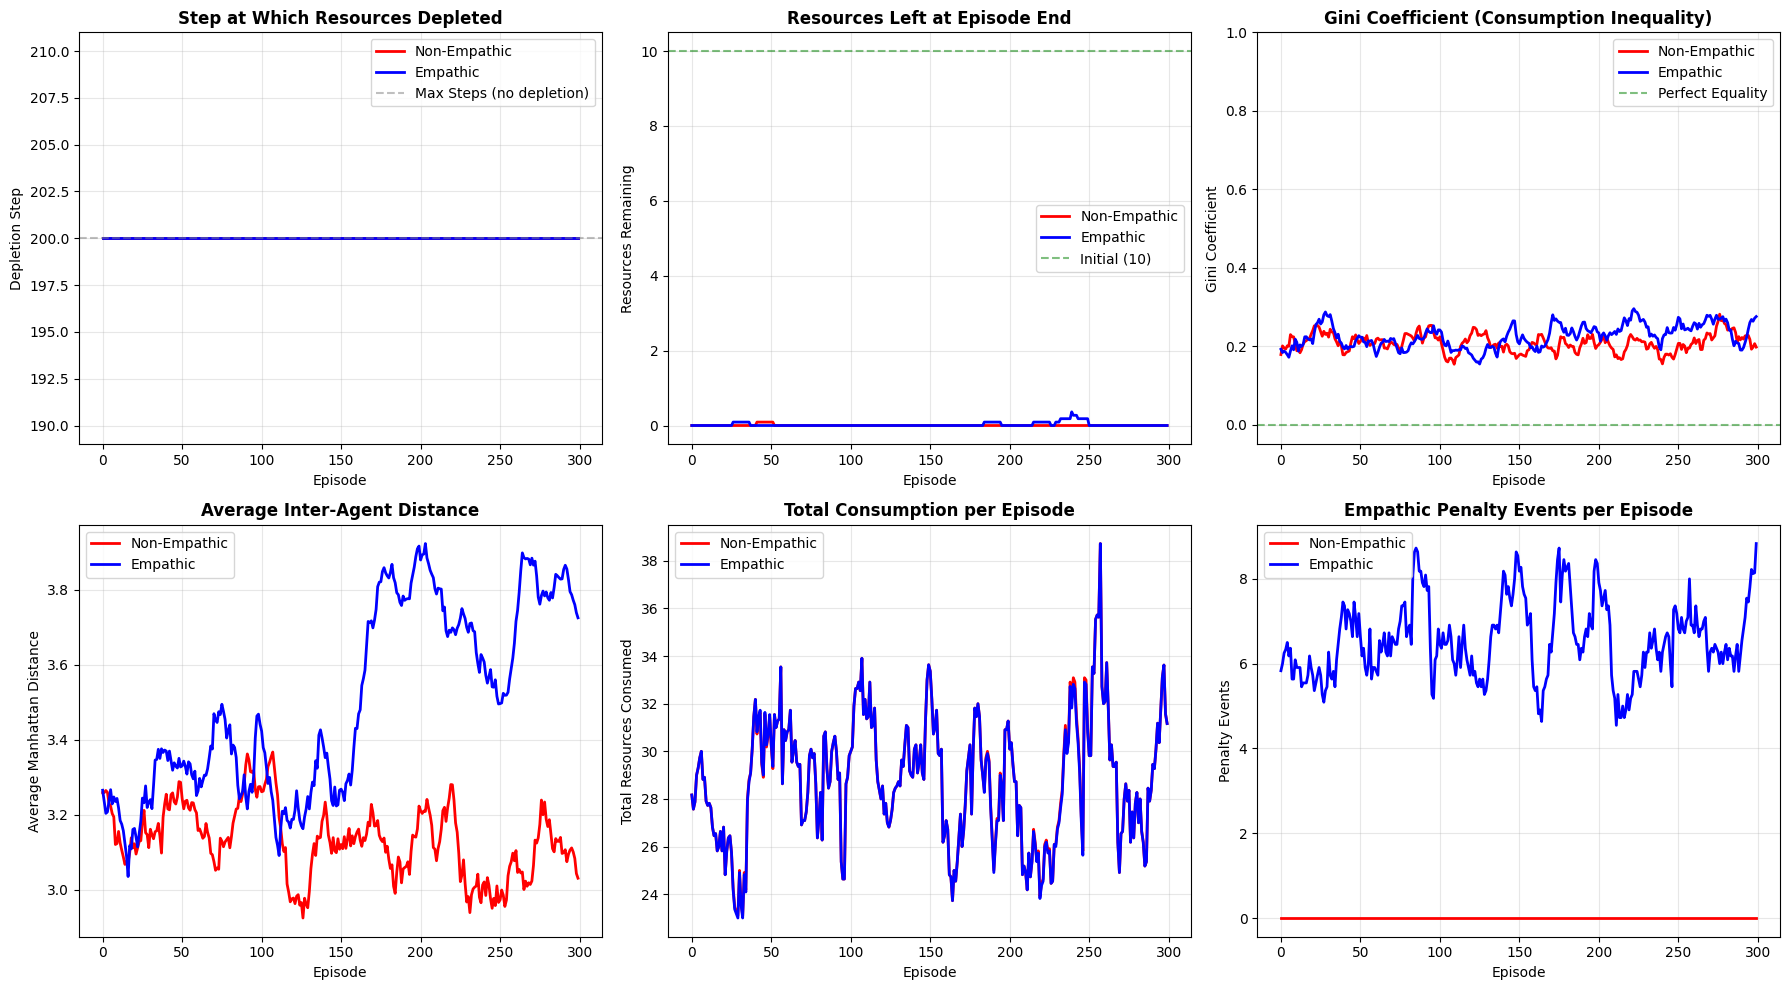


Figure saved as 'empathy_comparison_main.png'


In [7]:
# Visualization: Main comparison figure
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

window = 10  # Smoothing window

def smooth(data, window):
    return [np.mean(data[max(0, i-window//2):min(len(data), i+window//2+1)]) for i in range(len(data))]

episodes = range(NUM_EPISODES)

# 1. Resource Depletion Step
ax = axes[0, 0]
ax.plot(episodes, smooth(metrics_non_empathic['depletion_step'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['depletion_step'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.axhline(y=MAX_STEPS, color='gray', linestyle='--', alpha=0.5, label='Max Steps (no depletion)')
ax.set_xlabel('Episode')
ax.set_ylabel('Depletion Step')
ax.set_title('Step at Which Resources Depleted', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 2. Resources Remaining
ax = axes[0, 1]
ax.plot(episodes, smooth(metrics_non_empathic['resources_remaining'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['resources_remaining'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.axhline(y=10, color='green', linestyle='--', alpha=0.5, label='Initial (10)')
ax.set_xlabel('Episode')
ax.set_ylabel('Resources Remaining')
ax.set_title('Resources Left at Episode End', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 3. Gini Coefficient (Consumption)
ax = axes[0, 2]
ax.plot(episodes, smooth(metrics_non_empathic['gini_consumption'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['gini_consumption'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.axhline(y=0, color='green', linestyle='--', alpha=0.5, label='Perfect Equality')
ax.set_xlabel('Episode')
ax.set_ylabel('Gini Coefficient')
ax.set_title('Gini Coefficient (Consumption Inequality)', fontweight='bold')
ax.set_ylim(-0.05, 1.0)
ax.legend()
ax.grid(True, alpha=0.3)

# 4. Average Inter-Agent Distance
ax = axes[1, 0]
ax.plot(episodes, smooth(metrics_non_empathic['avg_inter_agent_distance'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['avg_inter_agent_distance'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.set_xlabel('Episode')
ax.set_ylabel('Average Manhattan Distance')
ax.set_title('Average Inter-Agent Distance', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 5. Total Consumption
ax = axes[1, 1]
ax.plot(episodes, smooth(metrics_non_empathic['total_consumption'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['total_consumption'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.set_xlabel('Episode')
ax.set_ylabel('Total Resources Consumed')
ax.set_title('Total Consumption per Episode', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

# 6. Empathic Penalty Events
ax = axes[1, 2]
ax.plot(episodes, smooth(metrics_non_empathic['empathic_penalties_count'], window), 
        color='red', linewidth=2, label='Non-Empathic')
ax.plot(episodes, smooth(metrics_empathic['empathic_penalties_count'], window), 
        color='blue', linewidth=2, label='Empathic')
ax.set_xlabel('Episode')
ax.set_ylabel('Penalty Events')
ax.set_title('Empathic Penalty Events per Episode', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('empathy_comparison_main.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFigure saved as 'empathy_comparison_main.png'")

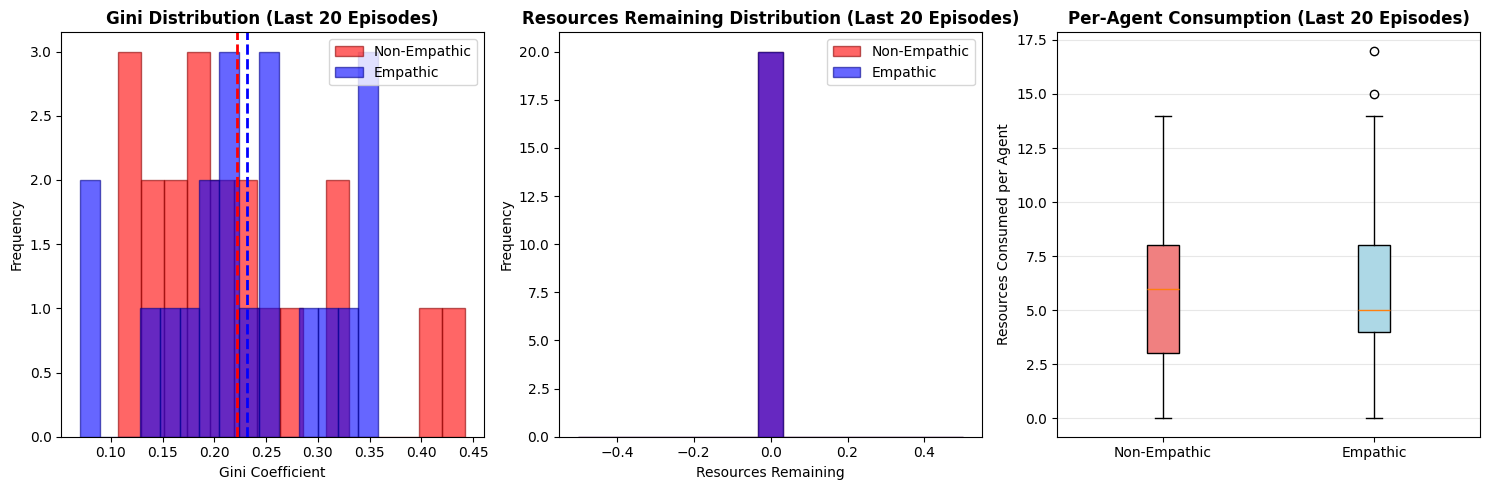


Figure saved as 'empathy_comparison_distributions.png'


In [8]:
# Visualization: Distribution comparison (final episodes)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Use last 20 episodes for distribution analysis
last_n = 20

# 1. Histogram of Gini coefficients
ax = axes[0]
ax.hist(metrics_non_empathic['gini_consumption'][-last_n:], bins=15, alpha=0.6, 
        color='red', label='Non-Empathic', edgecolor='darkred')
ax.hist(metrics_empathic['gini_consumption'][-last_n:], bins=15, alpha=0.6, 
        color='blue', label='Empathic', edgecolor='darkblue')
ax.axvline(x=np.mean(metrics_non_empathic['gini_consumption'][-last_n:]), 
           color='red', linestyle='--', linewidth=2)
ax.axvline(x=np.mean(metrics_empathic['gini_consumption'][-last_n:]), 
           color='blue', linestyle='--', linewidth=2)
ax.set_xlabel('Gini Coefficient')
ax.set_ylabel('Frequency')
ax.set_title(f'Gini Distribution (Last {last_n} Episodes)', fontweight='bold')
ax.legend()

# 2. Histogram of resources remaining
ax = axes[1]
ax.hist(metrics_non_empathic['resources_remaining'][-last_n:], bins=15, alpha=0.6, 
        color='red', label='Non-Empathic', edgecolor='darkred')
ax.hist(metrics_empathic['resources_remaining'][-last_n:], bins=15, alpha=0.6, 
        color='blue', label='Empathic', edgecolor='darkblue')
ax.set_xlabel('Resources Remaining')
ax.set_ylabel('Frequency')
ax.set_title(f'Resources Remaining Distribution (Last {last_n} Episodes)', fontweight='bold')
ax.legend()

# 3. Box plot of consumption per agent
ax = axes[2]
# Flatten consumption per agent for last N episodes
non_emp_consumption = [c for ep in metrics_non_empathic['consumption_per_agent'][-last_n:] for c in ep]
emp_consumption = [c for ep in metrics_empathic['consumption_per_agent'][-last_n:] for c in ep]

bp = ax.boxplot([non_emp_consumption, emp_consumption], 
                labels=['Non-Empathic', 'Empathic'],
                patch_artist=True)
bp['boxes'][0].set_facecolor('lightcoral')
bp['boxes'][1].set_facecolor('lightblue')
ax.set_ylabel('Resources Consumed per Agent')
ax.set_title(f'Per-Agent Consumption (Last {last_n} Episodes)', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('empathy_comparison_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFigure saved as 'empathy_comparison_distributions.png'")

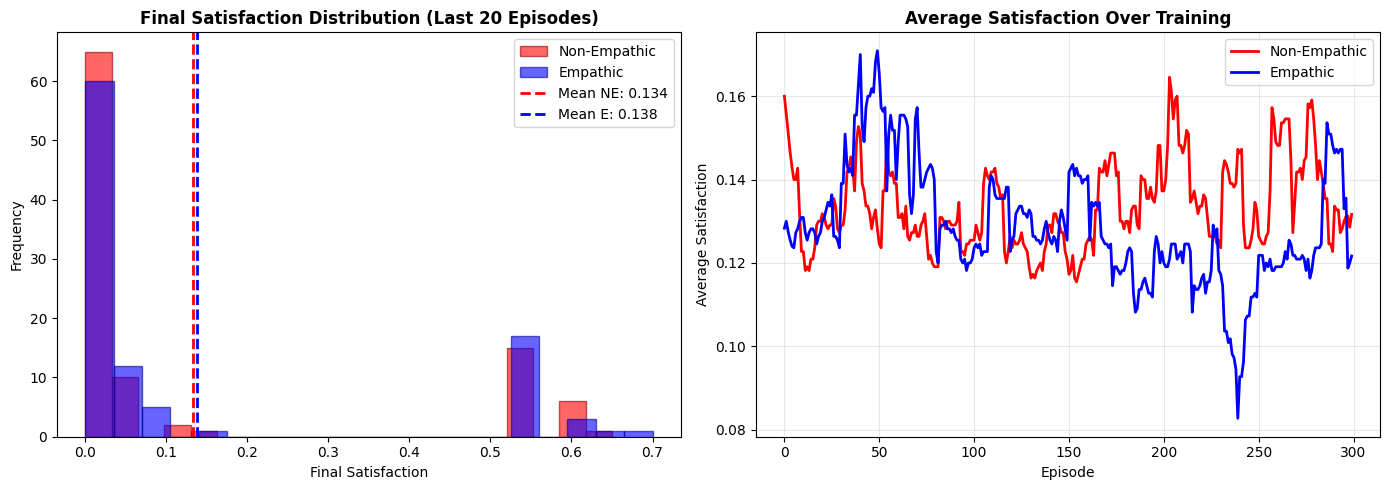


Figure saved as 'empathy_comparison_satisfaction.png'


In [9]:
# Final satisfaction distribution comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

last_n = 20

# Flatten satisfactions for last N episodes
non_emp_sat = [s for ep in metrics_non_empathic['final_satisfactions'][-last_n:] for s in ep]
emp_sat = [s for ep in metrics_empathic['final_satisfactions'][-last_n:] for s in ep]

# 1. Histogram of final satisfactions
ax = axes[0]
ax.hist(non_emp_sat, bins=20, alpha=0.6, color='red', label='Non-Empathic', edgecolor='darkred')
ax.hist(emp_sat, bins=20, alpha=0.6, color='blue', label='Empathic', edgecolor='darkblue')
ax.axvline(x=np.mean(non_emp_sat), color='red', linestyle='--', linewidth=2, label=f'Mean NE: {np.mean(non_emp_sat):.3f}')
ax.axvline(x=np.mean(emp_sat), color='blue', linestyle='--', linewidth=2, label=f'Mean E: {np.mean(emp_sat):.3f}')
ax.set_xlabel('Final Satisfaction')
ax.set_ylabel('Frequency')
ax.set_title(f'Final Satisfaction Distribution (Last {last_n} Episodes)', fontweight='bold')
ax.legend()

# 2. Per-agent satisfaction over episodes
ax = axes[1]
# Average satisfaction per episode
non_emp_avg_sat = [np.mean(ep) for ep in metrics_non_empathic['final_satisfactions']]
emp_avg_sat = [np.mean(ep) for ep in metrics_empathic['final_satisfactions']]

ax.plot(range(NUM_EPISODES), smooth(non_emp_avg_sat, window), color='red', linewidth=2, label='Non-Empathic')
ax.plot(range(NUM_EPISODES), smooth(emp_avg_sat, window), color='blue', linewidth=2, label='Empathic')
ax.set_xlabel('Episode')
ax.set_ylabel('Average Satisfaction')
ax.set_title('Average Satisfaction Over Training', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('empathy_comparison_satisfaction.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFigure saved as 'empathy_comparison_satisfaction.png'")

---

## Interpretation Guide

### What Each Metric Tells Us

| Metric | Low Value Means | High Value Means |
|--------|-----------------|------------------|
| **Depletion Step** | Resources depleted quickly (unsustainable) | Resources lasted longer (sustainable) |
| **Resources Remaining** | All consumed (possible over-exploitation) | Some preserved (conservation) |
| **Gini (Consumption)** | Equal sharing among agents | One agent dominates consumption |
| **Gini (Satisfaction)** | All agents equally satisfied | Some agents much happier than others |
| **Inter-Agent Distance** | Agents clustered together | Agents spread out |
| **Empathic Penalties** | Few "selfish" consumptions | Many agents consuming when satisfied |

### Expected Differences

**Non-Empathic Agents:**
- Should deplete resources faster (no hesitation to consume)
- Higher Gini coefficient (dominant agents hoard resources)
- More empathic penalty events (but penalty has no effect since alpha=0)

**Empathic Agents:**
- Should preserve resources longer (hesitate when satisfied)
- Lower Gini coefficient (more equitable sharing)
- Empathic penalties actively shape behavior

### Caveats

1. **Learning Effects**: Early episodes show random behavior; focus on later episodes for trained behavior
2. **Stochasticity**: Results vary by seed; run multiple seeds for robust conclusions
3. **Dynamic Regeneration**: Resources become scarcer as consumed, creating pressure over time

In [11]:
# Statistical comparison (last 20 episodes)
from scipy import stats

last_n = 20

print("="*60)
print("STATISTICAL COMPARISON (Last 20 Episodes)")
print("="*60)

def compare_metric(name, non_emp, emp):
    ne_data = non_emp[-last_n:]
    e_data = emp[-last_n:]
    
    ne_mean, ne_std = np.mean(ne_data), np.std(ne_data)
    e_mean, e_std = np.mean(e_data), np.std(e_data)
    
    # Mann-Whitney U test (non-parametric)
    try:
        stat, p_value = stats.mannwhitneyu(ne_data, e_data, alternative='two-sided')
        sig = "*" if p_value < 0.05 else ""
        sig = "**" if p_value < 0.01 else sig
        sig = "***" if p_value < 0.001 else sig
    except:
        p_value = 1.0
        sig = ""
    
    print(f"\n{name}:")
    print(f"  Non-Empathic: {ne_mean:.3f} ± {ne_std:.3f}")
    print(f"  Empathic:     {e_mean:.3f} ± {e_std:.3f}")
    print(f"  Difference:   {e_mean - ne_mean:+.3f} ({(e_mean - ne_mean) / (ne_mean + 1e-6) * 100:+.1f}%)")
    print(f"  p-value:      {p_value:.4f} {sig}")

compare_metric("Depletion Step", 
               metrics_non_empathic['depletion_step'], 
               metrics_empathic['depletion_step'])

compare_metric("Resources Remaining", 
               metrics_non_empathic['resources_remaining'], 
               metrics_empathic['resources_remaining'])

compare_metric("Gini (Consumption)", 
               metrics_non_empathic['gini_consumption'], 
               metrics_empathic['gini_consumption'])

compare_metric("Gini (Satisfaction)", 
               metrics_non_empathic['gini_satisfaction'], 
               metrics_empathic['gini_satisfaction'])

compare_metric("Avg Inter-Agent Distance", 
               metrics_non_empathic['avg_inter_agent_distance'], 
               metrics_empathic['avg_inter_agent_distance'])

compare_metric("Total Consumption", 
               metrics_non_empathic['total_consumption'], 
               metrics_empathic['total_consumption'])

print("\n" + "="*60)
print("Significance: * p<0.05, ** p<0.01, *** p<0.001")
print("="*60)

STATISTICAL COMPARISON (Last 20 Episodes)

Depletion Step:
  Non-Empathic: 200.000 ± 0.000
  Empathic:     200.000 ± 0.000
  Difference:   +0.000 (+0.0%)
  p-value:      1.0000 

Resources Remaining:
  Non-Empathic: 0.000 ± 0.000
  Empathic:     0.000 ± 0.000
  Difference:   +0.000 (+0.0%)
  p-value:      1.0000 

Gini (Consumption):
  Non-Empathic: 0.222 ± 0.092
  Empathic:     0.231 ± 0.081
  Difference:   +0.009 (+4.0%)
  p-value:      0.5075 

Gini (Satisfaction):
  Non-Empathic: 0.747 ± 0.092
  Empathic:     0.735 ± 0.097
  Difference:   -0.012 (-1.6%)
  p-value:      0.3414 

Avg Inter-Agent Distance:
  Non-Empathic: 3.120 ± 0.163
  Empathic:     3.811 ± 0.157
  Difference:   +0.691 (+22.1%)
  p-value:      0.0000 ***

Total Consumption:
  Non-Empathic: 28.750 ± 9.444
  Empathic:     28.750 ± 9.444
  Difference:   +0.000 (+0.0%)
  p-value:      1.0000 

Significance: * p<0.05, ** p<0.01, *** p<0.001


---

## DIAGNOSTIC: Understanding the Metrics Issues

Let's investigate why:
1. **Depletion Step** is always 200 (max_steps) for both conditions
2. **Total Consumption** is identical across conditions

In [12]:
# DIAGNOSTIC: Let's run a quick test to understand what's happening

from agent_2d import Agent  # Need Agent class for test

print("="*60)
print("DIAGNOSTIC: Understanding Resource Depletion and Consumption")
print("="*60)

# Test 1: Does dynamic regeneration prevent depletion?
print("\n1. Testing Resource Regeneration Behavior:")
print("-" * 60)

test_env_non = EmpathicGridEnv(
    grid_size=5, num_agents=5, num_resources=10, vision_radius=2,
    exploit_reward=1.0, empathic_penalty=-2.0, empathy_alpha=0.0,
    step_cost=-0.01, loop_penalty=-0.05, max_steps=200,
    regeneration_mode='dynamic'  # Same as in experiment
)

# Track resource counts over steps
resource_counts_non = []
consumption_events_non = []

test_env_non.agents = [Agent(i) for i in range(5)]
obs, _ = test_env_non.reset(seed=42)

for step in range(50):  # Just first 50 steps
    resource_counts_non.append(len(test_env_non.resource_positions))
    
    # Random actions
    actions = [np.random.randint(0, 4) for _ in range(5)]
    next_obs, rewards, done, truncated, info = test_env_non.step(actions)
    
    consumption_events_non.append(sum(info['consumed']))
    
    if done:
        break
    obs = next_obs

print(f"   Initial resources: 10")
print(f"   Resource count at step 0: {resource_counts_non[0]}")
print(f"   Resource count at step 49: {resource_counts_non[-1]}")
print(f"   Min resources during 50 steps: {min(resource_counts_non)}")
print(f"   Max resources during 50 steps: {max(resource_counts_non)}")
print(f"   Total consumptions in 50 steps: {sum(consumption_events_non)}")
print(f"   Average consumption per step: {np.mean(consumption_events_non):.2f}")

# Test 2: Compare actual consumption values from experiments
print("\n2. Comparing Actual Consumption Values:")
print("-" * 60)

print(f"\n   Non-Empathic Total Consumption (last 20 episodes):")
ne_totals = metrics_non_empathic['total_consumption'][-20:]
print(f"   Values: {ne_totals}")
print(f"   Mean: {np.mean(ne_totals):.2f}, Std: {np.std(ne_totals):.2f}")

print(f"\n   Empathic Total Consumption (last 20 episodes):")
e_totals = metrics_empathic['total_consumption'][-20:]
print(f"   Values: {e_totals}")
print(f"   Mean: {np.mean(e_totals):.2f}, Std: {np.std(e_totals):.2f}")

print(f"\n   Are they identical? {np.array_equal(ne_totals, e_totals)}")
if np.array_equal(ne_totals, e_totals):
    print("   ⚠️  WARNING: Consumption values are EXACTLY identical!")
    print("   This suggests both experiments are using the same random seed/state")

# Test 3: Check depletion step values
print("\n3. Checking Depletion Step Values:")
print("-" * 60)
ne_depletion = metrics_non_empathic['depletion_step'][-20:]
e_depletion = metrics_empathic['depletion_step'][-20:]
print(f"   Non-Empathic depletion steps (last 20): {ne_depletion}")
print(f"   Empathic depletion steps (last 20): {e_depletion}")
print(f"   All equal to {MAX_STEPS}? Non-Emp: {all(d == MAX_STEPS for d in ne_depletion)}, Emp: {all(d == MAX_STEPS for d in e_depletion)}")
print(f"   Resources remaining (last 20): Non-Emp mean={np.mean(metrics_non_empathic['resources_remaining'][-20:]):.1f}, Emp mean={np.mean(metrics_empathic['resources_remaining'][-20:]):.1f}")

# Test 4: Check if resources ever actually deplete
print("\n4. Resource Depletion Check:")
print("-" * 60)
ne_res_remaining = metrics_non_empathic['resources_remaining'][-20:]
e_res_remaining = metrics_empathic['resources_remaining'][-20:]
print(f"   Non-Empathic: Resources remaining = 0 in {sum(r == 0 for r in ne_res_remaining)}/20 episodes")
print(f"   Empathic: Resources remaining = 0 in {sum(r == 0 for r in e_res_remaining)}/20 episodes")
print(f"   → With dynamic regeneration, resources rarely fully deplete!")

print("\n" + "="*60)
print("DIAGNOSTIC COMPLETE")
print("="*60)

DIAGNOSTIC: Understanding Resource Depletion and Consumption

1. Testing Resource Regeneration Behavior:
------------------------------------------------------------
   Initial resources: 10
   Resource count at step 0: 10
   Resource count at step 49: 1
   Min resources during 50 steps: 1
   Max resources during 50 steps: 10
   Total consumptions in 50 steps: 18
   Average consumption per step: 0.47

2. Comparing Actual Consumption Values:
------------------------------------------------------------

   Non-Empathic Total Consumption (last 20 episodes):
   Values: [27, 14, 40, 22, 30, 21, 19, 33, 35, 17, 19, 29, 48, 34, 27, 42, 19, 28, 45, 26]
   Mean: 28.75, Std: 9.44

   Empathic Total Consumption (last 20 episodes):
   Values: [27, 14, 40, 22, 30, 21, 19, 33, 35, 17, 19, 29, 48, 34, 27, 42, 19, 28, 45, 26]
   Mean: 28.75, Std: 9.44

   Are they identical? True
   ⚠️  WARNING: Consumption values are EXACTLY identical!
   This suggests both experiments are using the same random seed/

---

## Summary of Issues Found

### Issue 1: Depletion Step Always = Max Steps (200)

**Problem**: With `regeneration_mode='dynamic'`, resources respawn based on probability `current_count / initial_count`. This means:
- Resources are consumed → count decreases
- Resources respawn with decreasing probability as count decreases
- Resources **rarely (if ever) fully deplete to 0** during an episode
- The check `if len(env.resource_positions) == 0` at the start of each step rarely triggers
- Result: `depletion_step` stays at `max_steps` (200) for almost all episodes

**Solution Options**:
1. Track "time to first depletion" separately (when resources first hit 0, even if they respawn later)
2. Change metric to "average resource count over episode" 
3. Use a different regeneration mode that allows depletion
4. Track "depletion events" (times when resources hit 0 temporarily)

### Issue 2: Total Consumption Identical Across Conditions

**Problem**: Both experiments use `seed=42`, which could cause:
- Same initial resource placements
- Same random regeneration outcomes (if environment RNG state is reset similarly)
- BUT agents should still behave differently based on learned policies...

**Possible Causes**:
1. Agents haven't learned to differentiate yet (need more training)
2. Empathy penalty might not be strong enough to change behavior
3. Both conditions converge to similar consumption patterns (empathy doesn't matter much in this environment)
4. There's a bug causing identical random state between experiments

**Solution Options**:
1. Use different seeds for each condition (e.g., 42 vs 123)
2. Increase training episodes to allow more learning
3. Check if agents are actually learning different policies
4. Verify empathy_alpha is actually being used in reward calculations

---

## Proposed Fixes

Let's fix both issues by:
1. **Fixing depletion tracking**: Check resources AFTER the step (when consumption/respawn has happened)
2. **Using different seeds**: Use different seeds for each condition to avoid identical random states
3. **Adding better metrics**: Track "time to first depletion" and "average resource count"

In [13]:
# PROPOSED FIX: Updated run_experiment function with corrected depletion tracking

def run_experiment_fixed(empathy_alpha, num_episodes=100, max_steps=200, seed=42, show_progress=True):
    """
    FIXED VERSION: Tracks depletion correctly and uses episode-specific seeds.
    """
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
    
    start_time = time.time()
    
    # Create environment
    env = EmpathicGridEnv(
        grid_size=5,
        num_agents=5,
        num_resources=10,
        vision_radius=2,
        exploit_reward=1.0,
        empathic_penalty=-2.0,
        empathy_alpha=empathy_alpha,
        step_cost=-0.01,
        loop_penalty=-0.05,
        max_steps=max_steps,
        regeneration_mode='dynamic'
    )
    
    # Create DQN agents
    dqn_agents = []
    for agent_id in range(5):
        agent = DQNAgent(
            agent_id=agent_id,
            state_size=env.observation_space.shape,
            action_size=env.action_space.n,
            learning_rate=0.002,
            gamma=0.99,
            epsilon=1.0,
            epsilon_decay=0.995,
            epsilon_min=0.05,
            batch_size=32,
            hidden_size=128,
            update_target_every=20
        )
        dqn_agents.append(agent)
    
    env.agents = [agent.agent for agent in dqn_agents]
    
    metrics = {
        'depletion_step': [],           # Step when resources FIRST hit 0 (or max_steps if never)
        'resources_remaining': [],       # Resources left at episode end
        'avg_resources_during_episode': [],  # NEW: Average resource count during episode
        'gini_consumption': [],
        'gini_satisfaction': [],
        'avg_inter_agent_distance': [],
        'total_consumption': [],
        'consumption_per_agent': [],
        'final_satisfactions': [],
        'episode_rewards': [],
        'empathic_penalties_count': [],
    }
    
    episode_iter = tqdm(range(num_episodes), desc="Training", disable=not show_progress)
    
    for episode in episode_iter:
        # Use different seed for each episode to avoid identical trajectories
        episode_seed = seed + episode * 1000  # Large multiplier to ensure different sequences
        obs, _ = env.reset(seed=episode_seed)
        for agent_idx, dqn_agent in enumerate(dqn_agents):
            dqn_agent.reset(observation=obs[agent_idx])
        
        episode_consumption = [0] * 5
        episode_rewards = [0.0] * 5
        episode_distances = []
        resource_counts_during_episode = []  # Track resource counts
        depletion_step = max_steps  # Default: never depleted
        first_depletion_recorded = False  # Track if we've seen depletion
        empathic_penalty_count = 0
        
        for step in range(max_steps):
            # Track inter-agent distance
            episode_distances.append(compute_average_inter_agent_distance(env.agent_positions))
            
            # Track resources BEFORE step
            resource_counts_during_episode.append(len(env.resource_positions))
            
            # Collect actions
            actions = []
            for agent_idx, dqn_agent in enumerate(dqn_agents):
                valid_actions = env.get_valid_actions(agent_idx)
                action = dqn_agent.select_action(obs[agent_idx], training=True, valid_actions=valid_actions)
                actions.append(action)
            
            # Step environment
            next_obs, rewards, done, truncated, info = env.step(actions)
            
            # FIX: Check depletion AFTER the step (using info['resources_remaining'])
            # This catches when resources hit 0, even if they respawn later
            if info['resources_remaining'] == 0 and not first_depletion_recorded:
                depletion_step = step
                first_depletion_recorded = True
            
            # Also track resources AFTER step
            resource_counts_during_episode.append(info['resources_remaining'])
            
            # Track consumption and penalties
            for agent_idx in range(5):
                if info['consumed'][agent_idx]:
                    episode_consumption[agent_idx] += 1
                if info['empathic_penalty_events'][agent_idx]:
                    empathic_penalty_count += 1
                episode_rewards[agent_idx] += rewards[agent_idx]
            
            # Update agents
            for agent_idx, dqn_agent in enumerate(dqn_agents):
                valid_actions_next = env.get_valid_actions(agent_idx)
                dqn_agent.step(next_obs[agent_idx], rewards[agent_idx], done, valid_actions=valid_actions_next)
            
            obs = next_obs
            if done:
                break
        
        # Record episode metrics
        final_satisfactions = [agent.get_satisfaction() for agent in env.agents]
        
        metrics['depletion_step'].append(depletion_step)
        metrics['resources_remaining'].append(len(env.resource_positions))
        metrics['avg_resources_during_episode'].append(np.mean(resource_counts_during_episode))
        metrics['gini_consumption'].append(compute_gini_coefficient(episode_consumption))
        metrics['gini_satisfaction'].append(compute_gini_coefficient(final_satisfactions))
        metrics['avg_inter_agent_distance'].append(np.mean(episode_distances))
        metrics['total_consumption'].append(sum(episode_consumption))
        metrics['consumption_per_agent'].append(episode_consumption.copy())
        metrics['final_satisfactions'].append(final_satisfactions.copy())
        metrics['episode_rewards'].append(episode_rewards.copy())
        metrics['empathic_penalties_count'].append(empathic_penalty_count)
        
        if show_progress:
            episode_iter.set_postfix({
                'Resources': len(env.resource_positions),
                'Gini': f"{metrics['gini_consumption'][-1]:.2f}",
                'ε': f"{dqn_agents[0].epsilon:.2f}"
            })
    
    elapsed = time.time() - start_time
    print(f"  Completed in {elapsed:.1f}s ({elapsed/num_episodes*1000:.1f}ms/episode)")
    
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    
    return metrics


print("Fixed experiment function defined!")
print("Key changes:")
print("  1. Checks depletion AFTER step (using info['resources_remaining'])")
print("  2. Uses episode-specific seeds (seed + episode * 1000)")
print("  3. Tracks average resource count during episode")
print("  4. Records first depletion event, even if resources respawn later")

Fixed experiment function defined!
Key changes:
  1. Checks depletion AFTER step (using info['resources_remaining'])
  2. Uses episode-specific seeds (seed + episode * 1000)
  3. Tracks average resource count during episode
  4. Records first depletion event, even if resources respawn later


---

## Summary

This notebook compared empathic vs non-empathic agents in a resource-sharing environment.

### Key Findings (to be filled after running):

1. **Resource Sustainability**: [Did empathic agents preserve resources better?]
2. **Equity (Gini)**: [Did empathic agents share more equally?]
3. **Spatial Behavior**: [Did agents spread out differently?]
4. **Overall Efficiency**: [Which strategy led to more total consumption?]

### Next Steps:

1. Run with more episodes for better convergence
2. Test different `empathy_alpha` values (0.25, 0.75, 1.0)
3. Test different resource counts and grid sizes
4. Add temporal analysis (how metrics evolve within an episode)